# Урок 3. Метрики: на ком ошибается модель

Модель: логистическая регрессия на 4 признаках (`Pclass`, `Sex_num`, `Age`, `Fare`).
Тест: 179 случайных пассажиров (`random_state=42`).

## 0. Подготовка: данные, разбиение, обучение

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, classification_report)

# Данные: пол переводим в число (модель понимает только числа)
df = pd.read_csv("../data/titanic.csv")
df["Sex_num"] = df["Sex"].map({"male": 0, "female": 1})

features4 = ["Pclass", "Sex_num", "Age", "Fare"]
y = df["Survived"]

# Делим: 80% учёба, 20% экзамен (179 человек)
X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, random_state=42, stratify=y
)

# Модель = заполнить пропуски медианой + логистическая регрессия
model = make_pipeline(SimpleImputer(strategy="median"),
                      LogisticRegression(max_iter=1000))
model.fit(X_train[features4], y_train)        # учится
pred = model.predict(X_test[features4])        # угадывает 0 или 1

## 1. Матрица ошибок и отчёт

Строки — правда, столбцы — ответ модели.

In [2]:
print(confusion_matrix(y_test, pred))
print()
print(classification_report(y_test, pred, target_names=["Погиб", "Выжил"]))

[[94 16]
 [22 47]]

              precision    recall  f1-score   support

       Погиб       0.81      0.85      0.83       110
       Выжил       0.75      0.68      0.71        69

    accuracy                           0.79       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179



**Вывод:** из 179 модель угадала 94 + 47 = 141 (accuracy 0.79).
Ошибки: 22 пропуска (выжил, а модель сказала «погиб») и 16 ложных тревог (погиб, а модель сказала «выжил»).
Погибших модель узнаёт лучше (recall 0.85), чем выживших (recall 0.68).

## 2. Правило «женщины выжили» против модели

In [3]:
# Правило: ответ = пол (женщина = 1 = «выжил», мужчина = 0 = «погиб»)
print("Правило:\n", confusion_matrix(y_test, X_test["Sex_num"]))
print("Модель:\n", confusion_matrix(y_test, pred))

Правило:
 [[94 16]
 [24 45]]
Модель:
 [[94 16]
 [22 47]]


In [4]:
# Кто именно эти люди? Таблица там, где правило и модель ответили по-разному
diff = X_test[["Name", "Sex", "Pclass", "Age"]].copy()
diff["правда"] = y_test.values
diff["правило"] = X_test["Sex_num"].values
diff["модель"] = pred
diff[diff["правило"] != diff["модель"]]

,Name,Sex,Pclass,Age,правда,правило,модель
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,3,36.0,1,1,0
27,"Fortune, Mr. Charles Alexander",male,1,19.0,0,0,1
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,3,35.0,1,1,0
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,3,40.0,0,1,0
679,"Cardeza, Mr. Thomas Drake Martinez",male,1,36.0,1,0,1
607,"Daniel, Mr. Robert Williams",male,1,27.0,1,0,1
802,"Carter, Master. William Thornton II",male,1,11.0,1,0,1
484,"Bishop, Mr. Dickinson H",male,1,25.0,1,0,1


**Вывод:** по числам модель исправила 2 ошибки (пропуски 24 → 22). Но на самом деле правило и модель отвечают по-разному на **8** людях:
модель исправила 5 ошибок правила (4 выживших мужчины 1-го класса и 1 погибшая женщина 3-го класса), но сделала 3 новых.
Одинаковые числа в матрице — не значит одинаковые люди.

## 3. Матрица ошибок картинкой

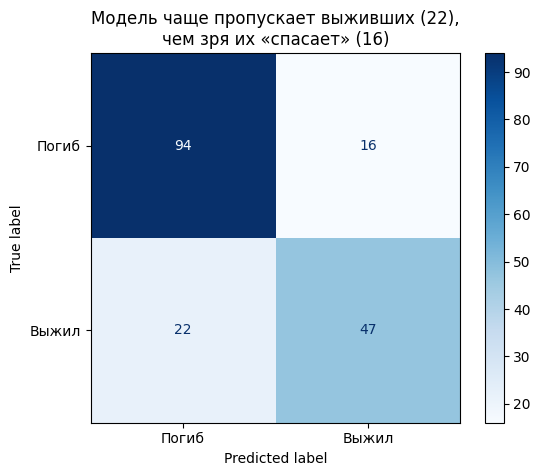

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Погиб", "Выжил"], cmap="Blues"
)
plt.title("Модель чаще пропускает выживших (22),\nчем зря их «спасает» (16)")
plt.show()

## 4. Порог для спасателя: recall ≥ 0.9

Обычно модель говорит «выжил», если вероятность ≥ 0.5. Понижаем порог, чтобы никого не пропустить.

In [6]:
proba = model.predict_proba(X_test[features4])[:, 1]   # вероятность «выжил» для каждого

for threshold in [0.05, 0.09, 0.1, 0.15, 0.2, 0.25, 0.3]:
    pred_t = (proba >= threshold).astype(int)          # 1, если вероятность выше порога
    print(f"порог {threshold:.2f}: "
          f"precision = {precision_score(y_test, pred_t):.2f}, "
          f"recall = {recall_score(y_test, pred_t):.3f}, "
          f"«выжил» сказано про {pred_t.sum()} из {len(pred_t)}")

порог 0.05: precision = 0.39, recall = 1.000, «выжил» сказано про 179 из 179
порог 0.09: precision = 0.41, recall = 0.971, «выжил» сказано про 163 из 179
порог 0.10: precision = 0.47, recall = 0.899, «выжил» сказано про 133 из 179
порог 0.15: precision = 0.55, recall = 0.884, «выжил» сказано про 110 из 179
порог 0.20: precision = 0.55, recall = 0.841, «выжил» сказано про 105 из 179
порог 0.25: precision = 0.62, recall = 0.826, «выжил» сказано про 92 из 179
порог 0.30: precision = 0.65, recall = 0.812, «выжил» сказано про 86 из 179


**Вывод:** порог 0.1 даёт recall 0.899 — чуть меньше 0.9. Нужен порог **0.09**: recall 0.97, но precision падает до 0.41
(6 из 10 «тревог» ложные). На пороге 0.05 модель говорит «выжил» про **всех** — recall 1.0, но такая модель ничего не различает.

## 5. Вопрос: 1 больной из 1000

Accuracy — 99,9%: модель правильно назвала здоровыми 999 из 1000 человек.
Recall — 0%: она не обнаружила единственного больного.

Врачу я бы показал recall, потому что он показывает, какую долю больных модель находит. Здесь высокая accuracy вводит в заблуждение: модель пропустила всех больных.
При этом для выбора медицинской модели важно учитывать и ложные тревоги (precision): иначе модель будет отправлять на анализы всех подряд.